In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("/data/raw/directory.csv")

: 

In [23]:
df.head()

,Brand,Store Number,Store Name,Ownership Type,Street Address,City,State/Province,Country,Postcode,Phone Number,Timezone,Longitude,Latitude
0,Starbucks,47370-257954,"Meritxell, 96",Licensed,"Av. Meritxell, 96",Andorra la Vella,7,AD,AD500,376818720,GMT+1:00 Europe/Andorra,1.53,42.51
1,Starbucks,22331-212325,Ajman Drive Thru,Licensed,"1 Street 69, Al Jarf",Ajman,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.42
2,Starbucks,47089-256771,Dana Mall,Licensed,Sheikh Khalifa Bin Zayed St.,Ajman,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.39
3,Starbucks,22126-218024,Twofour 54,Licensed,Al Salam Street,Abu Dhabi,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.38,24.48
4,Starbucks,17127-178586,Al Ain Tower,Licensed,"Khaldiya Area, Abu Dhabi Island",Abu Dhabi,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.54,24.51


## Initial Exploration

In [24]:
print(f"{'=' * 40}")
print("STARBUCKS DIRECTORY INITIAL EXPLORATION")
print(f"{'=' * 40}")

print("\nShape:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn Names:")
print(list(df.columns))

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values")
print(df.isna().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

STARBUCKS DIRECTORY INITIAL EXPLORATION

Shape:
Rows: 25600
Columns: 13

Column Names:
['Brand', 'Store Number', 'Store Name', 'Ownership Type', 'Street Address', 'City', 'State/Province', 'Country', 'Postcode', 'Phone Number', 'Timezone', 'Longitude', 'Latitude']

Data Types:
Brand                 str
Store Number          str
Store Name            str
Ownership Type        str
Street Address        str
City                  str
State/Province        str
Country               str
Postcode              str
Phone Number          str
Timezone              str
Longitude         float64
Latitude          float64
dtype: object

Missing Values
Brand                0
Store Number         0
Store Name           0
Ownership Type       0
Street Address       2
City                15
State/Province       0
Country              0
Postcode          1522
Phone Number      6861
Timezone             0
Longitude            1
Latitude             1
dtype: int64

Duplicate Rows
0


## Data Cleaning

### Standardizing Column Names

To ensure consistent syntax and prevent issues during downstream analysis, we convert all DataFrame column names to lowercase and replace spaces with underscores.

In [25]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.rename(
    columns={
        'state/province': 'state'
    }
)

# Adds a row_id column starting from 1
df.insert(0, 'row_id', range(1, len(df) + 1))

print(list(df.columns))


['row_id', 'brand', 'store_number', 'store_name', 'ownership_type', 'street_address', 'city', 'state', 'country', 'postcode', 'phone_number', 'timezone', 'longitude', 'latitude']


## Feature Engineering

In [26]:
df['continent'] = (
    df['timezone']
    .str.split(' ')
    .str[1]
    .str.split('/')
    .str[0]
)

df['city'] = (
    df['timezone']
    .str.split(' ')
    .str[1]
    .str.split('/')
    .str[1]
)

df

,row_id,brand,store_number,store_name,ownership_type,street_address,city,state,country,postcode,phone_number,timezone,longitude,latitude,continent
0,1,Starbucks,47370-257954,"Meritxell, 96",Licensed,"Av. Meritxell, 96",Andorra,7,AD,AD500,376818720,GMT+1:00 Europe/Andorra,1.53,42.51,Europe
1,2,Starbucks,22331-212325,Ajman Drive Thru,Licensed,"1 Street 69, Al Jarf",Dubai,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.42,Asia
2,3,Starbucks,47089-256771,Dana Mall,Licensed,Sheikh Khalifa Bin Zayed St.,Dubai,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.39,Asia
3,4,Starbucks,22126-218024,Twofour 54,Licensed,Al Salam Street,Dubai,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.38,24.48,Asia
4,5,Starbucks,17127-178586,Al Ain Tower,Licensed,"Khaldiya Area, Abu Dhabi Island",Dubai,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.54,24.51,Asia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25595,25596,Starbucks,21401-212072,Rex,Licensed,"141 Nguyễn Huệ, Quận 1, Góc đường Pasteur và L...",Saigon,SG,VN,70000,08 3824 4668,GMT+000000 Asia/Saigon,106.70,10.78,Asia
25596,25597,Starbucks,24010-226985,Panorama,Licensed,"SN-44, Tòa Nhà Panorama, 208 Trần Văn Trà, Quận 7",Saigon,SG,VN,70000,08 5413 8292,GMT+000000 Asia/Saigon,106.71,10.72,Asia
25597,25598,Starbucks,47608-253804,Rosebank Mall,Licensed,"Cnr Tyrwhitt and Cradock Avenue, Rosebank",Johannesburg,GT,ZA,2194,27873500159,GMT+000000 Africa/Johannesburg,28.04,-26.15,Africa
25598,25599,Starbucks,47640-253809,Menlyn Maine,Licensed,"Shop 61B, Central Square, Cnr Aramist & Coroba...",Johannesburg,GT,ZA,181,NaN,GMT+000000 Africa/Johannesburg,28.28,-25.79,Africa


### Data Type Optimization
To optimize memory consumption and speed up downstream filtering/grouping operations, we convert the `continent` column from a generic string `object` type to a pandas `category` data type.


In [27]:
print(df.dtypes)

row_id              int64
brand                 str
store_number          str
store_name            str
ownership_type        str
street_address        str
city               object
state                 str
country               str
postcode              str
phone_number          str
timezone              str
longitude         float64
latitude          float64
continent          object
dtype: object


In [28]:
df['continent'] = df['continent'].astype('category')

print(df.dtypes)

row_id               int64
brand                  str
store_number           str
store_name             str
ownership_type         str
street_address         str
city                object
state                  str
country                str
postcode               str
phone_number           str
timezone               str
longitude          float64
latitude           float64
continent         category
dtype: object


## Analytical Dataset Overview

In [29]:
print("Shape:", df.shape)

print(len(df))
print("\nColumns:")
print(list(df.columns))

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (25600, 15)
25600

Columns:
['row_id', 'brand', 'store_number', 'store_name', 'ownership_type', 'street_address', 'city', 'state', 'country', 'postcode', 'phone_number', 'timezone', 'longitude', 'latitude', 'continent']

Data Types:
row_id               int64
brand                  str
store_number           str
store_name             str
ownership_type         str
street_address         str
city                object
state                  str
country                str
postcode               str
phone_number           str
timezone               str
longitude          float64
latitude           float64
continent         category
dtype: object

Missing Values:
row_id               0
brand                0
store_number         0
store_name           0
ownership_type       0
street_address       2
city                 0
state                0
country              0
postcode          1522
phone_number      6861
timezone             0
longitude            1
latitude             1
co

## Checking Grain by confirming duplicate using our ID as store_number column

In [30]:
df[df.duplicated("store_number", keep=False)]

,row_id,brand,store_number,store_name,ownership_type,street_address,city,state,country,postcode,phone_number,timezone,longitude,latitude,continent
8028,8029,Starbucks,19773-160973,Yoido IFC Mall - 1F,Joint Venture,"23 & 23-1, Yoido-Dong, Yongdongpo-Gu, 1F, #101",Seoul,11,KR,153-023,NaN,GMT+09:00 Asia/Seoul,NaN,NaN,Asia
8159,8160,Starbucks,19773-160973,Yoido IFC Mall - 1F,Joint Venture,"23 & 23-1, Yoido-Dong, Yongdongpo-Gu, 1F, #101",Seoul,11,KR,153-023,NaN,GMT+09:00 Asia/Seoul,126.92,37.53,Asia


### Remove the duplicate store_number, keep the last because it has more info

In [31]:
df = df.drop_duplicates("store_number", keep="last").reset_index(drop=True)

### Confirm if its dropped

In [32]:
df[df.duplicated("store_number", keep=False)]

,row_id,brand,store_number,store_name,ownership_type,street_address,city,state,country,postcode,phone_number,timezone,longitude,latitude,continent


In [33]:
from pathlib import Path

# save enrolment analysis to data processed folder
processed_path = Path("../data/processed")
processed_path.mkdir(parents=True, exist_ok=True)

df.to_csv(
    processed_path / "starbucks_analysis.csv",
    index=False
)

print("Saved to:", processed_path / "starbucks_analysis.csv")

Saved to: ..\data\processed\starbucks_analysis.csv


## Exploratory Data Analysis

### Brand Level EDA

In [34]:
df.head()

,row_id,brand,store_number,store_name,ownership_type,street_address,city,state,country,postcode,phone_number,timezone,longitude,latitude,continent
0,1,Starbucks,47370-257954,"Meritxell, 96",Licensed,"Av. Meritxell, 96",Andorra,7,AD,AD500,376818720,GMT+1:00 Europe/Andorra,1.53,42.51,Europe
1,2,Starbucks,22331-212325,Ajman Drive Thru,Licensed,"1 Street 69, Al Jarf",Dubai,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.42,Asia
2,3,Starbucks,47089-256771,Dana Mall,Licensed,Sheikh Khalifa Bin Zayed St.,Dubai,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.39,Asia
3,4,Starbucks,22126-218024,Twofour 54,Licensed,Al Salam Street,Dubai,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.38,24.48,Asia
4,5,Starbucks,17127-178586,Al Ain Tower,Licensed,"Khaldiya Area, Abu Dhabi Island",Dubai,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.54,24.51,Asia


In [35]:
brand_count = df.groupby('brand')['store_number'].nunique().reset_index().sort_values('store_number', ascending=False)

print(brand_count)

                   brand  store_number
2              Starbucks         25248
3                Teavana           348
1        Evolution Fresh             2
0  Coffee House Holdings             1


In [36]:
brand_count['percentage'] = (
    brand_count['store_number'] /
    brand_count['store_number'].sum()
    * 100
).round(2)

brand_count


,brand,store_number,percentage
2,Starbucks,25248,98.63
3,Teavana,348,1.36
1,Evolution Fresh,2,0.01
0,Coffee House Holdings,1,0.00


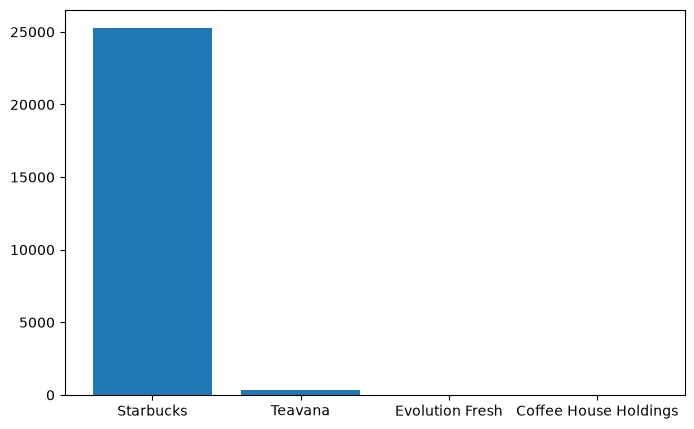

In [37]:
plt.figure(figsize=(8,5))

plt.bar(
    brand_count['brand'],
    brand_count['store_number']
)

plt.show()

In [38]:
brand_ownership_type = df.groupby(['brand', 'ownership_type'])['store_number'].agg(['nunique', 'count']).reset_index()

print(brand_ownership_type)

                   brand ownership_type  nunique  count
0  Coffee House Holdings  Company Owned        1      1
1        Evolution Fresh  Company Owned        2      2
2              Starbucks  Company Owned    11581  11581
3              Starbucks      Franchise      317    317
4              Starbucks  Joint Venture     3975   3975
5              Starbucks       Licensed     9375   9375
6                Teavana  Company Owned      348    348


### Starbucks status

In [39]:
df_starbucks = df[df['brand'] == 'Starbucks']

df_starbucks

,row_id,brand,store_number,store_name,ownership_type,street_address,city,state,country,postcode,phone_number,timezone,longitude,latitude,continent
0,1,Starbucks,47370-257954,"Meritxell, 96",Licensed,"Av. Meritxell, 96",Andorra,7,AD,AD500,376818720,GMT+1:00 Europe/Andorra,1.53,42.51,Europe
1,2,Starbucks,22331-212325,Ajman Drive Thru,Licensed,"1 Street 69, Al Jarf",Dubai,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.42,Asia
2,3,Starbucks,47089-256771,Dana Mall,Licensed,Sheikh Khalifa Bin Zayed St.,Dubai,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.39,Asia
3,4,Starbucks,22126-218024,Twofour 54,Licensed,Al Salam Street,Dubai,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.38,24.48,Asia
4,5,Starbucks,17127-178586,Al Ain Tower,Licensed,"Khaldiya Area, Abu Dhabi Island",Dubai,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.54,24.51,Asia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25594,25596,Starbucks,21401-212072,Rex,Licensed,"141 Nguyễn Huệ, Quận 1, Góc đường Pasteur và L...",Saigon,SG,VN,70000,08 3824 4668,GMT+000000 Asia/Saigon,106.70,10.78,Asia
25595,25597,Starbucks,24010-226985,Panorama,Licensed,"SN-44, Tòa Nhà Panorama, 208 Trần Văn Trà, Quận 7",Saigon,SG,VN,70000,08 5413 8292,GMT+000000 Asia/Saigon,106.71,10.72,Asia
25596,25598,Starbucks,47608-253804,Rosebank Mall,Licensed,"Cnr Tyrwhitt and Cradock Avenue, Rosebank",Johannesburg,GT,ZA,2194,27873500159,GMT+000000 Africa/Johannesburg,28.04,-26.15,Africa
25597,25599,Starbucks,47640-253809,Menlyn Maine,Licensed,"Shop 61B, Central Square, Cnr Aramist & Coroba...",Johannesburg,GT,ZA,181,NaN,GMT+000000 Africa/Johannesburg,28.28,-25.79,Africa


In [40]:
sb_level_analysis = df_starbucks.groupby(['brand','continent', 'city', 'ownership_type'])['store_number'].nunique().reset_index()

sb_level_analysis

,brand,continent,city,ownership_type,store_number
0,Starbucks,Africa,Cairo,Licensed,31
1,Starbucks,Africa,Casablanca,Licensed,9
2,Starbucks,Africa,Johannesburg,Licensed,3
3,Starbucks,America,Anchorage,Company Owned,8
4,Starbucks,America,Anchorage,Licensed,40
...,...,...,...,...,...
133,Starbucks,Europe,Zurich,Company Owned,51
134,Starbucks,Europe,Zurich,Licensed,4
135,Starbucks,Pacific,Auckland,Licensed,24
136,Starbucks,Pacific,Honolulu,Company Owned,62


In [41]:
sb_continent = (
    df_starbucks.groupby('continent')
    .agg(
        state_count=('city', 'nunique'),
        store_count=('store_number', 'nunique')
    )
)
sb_continent

,state_count,store_count
continent,,
Africa,3,43
America,37,15693
Asia,28,7406
Atlantic,1,1
Australia,3,22
Etc,1,7
Europe,26,1954
Pacific,2,122


In [42]:
sb_continent = (
    df_starbucks.groupby(['continent', 'ownership_type'])
)
sb_continent